# ABC-SMC: recurrence forecast and next-visit timing for one mechanistic model

This notebook is the pipeline, the figures and the usage guide for `ovca/abc_smc.py`.
All data are synthetic (`data/synthetic_data.csv`, made by `ovca/generator.py`).

**Question.** At any time point $t_\text{now}$, given a patient's CA-125 readings so far:
how uncertain is the forecast, when should the next CA-125 be measured, and does the
uncertainty shrink after that measurement?

**Model** (the poster model, `growth_death`): $\frac{dT}{dt} = (\gamma - \delta D(t))\,T$,
one set of parameters for the whole course. Surgery does two things:
- removes tumour: $T(t_s^+) = q\,T(t_s^-)$;
- shifts the parameters: $\log\gamma_\text{post} = \log\gamma_\text{pre} + \Delta_\gamma$,
  $\log\delta_\text{post} = \log\delta_\text{pre} + \Delta_\delta$.

Sampled parameters (all on the log scale): $\log\gamma_\text{pre}, \log\delta_\text{pre},
\Delta_\gamma, \Delta_\delta, \log q, \log \text{CA125}_0$.

**ABC-SMC.** The simulator is the model plus 15% lognormal assay noise. The distance between
simulated and observed readings is a weighted RMS of log differences. All readings are used as
they are, including those below 35 U/mL:

$$r_i = \log\text{sim}_i - \log\text{obs}_i, \qquad
d = \sqrt{\textstyle\sum_i w_i r_i^2 / \sum_i w_i}, \qquad
w_i = e^{-(t_\text{now} - t_i)/\tau}\ \text{(optional time decay)}.$$

Optionally (`censor_below=35`, the workshop RMSE convention) a reading below 35 only says
"below 35": $r_i = \log\max(\text{sim}_i, 35) - \log\max(\text{obs}_i, 35)$. Section 7b
shows why the default is to use the values.

Generations shrink $\varepsilon$ to the median of the previous distances, until fewer than 2%
of proposals are accepted.

## 0. Setup

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ovca import abc_smc as A, calibration, config as C, generator
from ovca.models import get_model

DATA_C, MODEL_C, INK, MUTED, GRID, DROP_C, BG = (
    "#2a78d6", "#eb6834", "#1f1f1e", "#8a897f", "#e6e5e0", "#b9b8b0", "#fcfcfb")
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "figure.facecolor": BG, "axes.facecolor": BG})

model = get_model("growth_death")
CUT = C.CA125_CUTOFF

## 1. Data

Load the synthetic cohort, or generate it if `data/` is empty. The first 30 patients are the
training set (used only to build a prior), the other 30 are test patients.
`A.patient_inputs` returns one patient's clinic readings (months, CA-125), treatment schedule and
daily rows (the daily rows hold the hidden truth and let us "measure" on any day later).

In [2]:
path = generator.DATA / generator.DATA_FILE
if not path.exists():
    generator.save(generator.generate_cohort(model)[0])
data = pd.read_csv(path)
readings, truth = generator.load()
train_ids, test_ids = list(truth.patient[:30]), list(truth.patient[30:])
print(f"{truth.shape[0]} patients, {len(readings)} clinic readings; "
      f"train {len(train_ids)}, test {len(test_ids)}")

t_obs, y_obs, sched, daily = A.patient_inputs(data, test_ids[0])
pd.DataFrame({"month": t_obs.round(2), "CA125": y_obs.round(1)}).head(12)

60 patients, 1000 clinic readings; train 30, test 30


,month,CA125
0,0.00,1172.7
1,2.00,482.7
2,4.00,346.6
3,5.90,124.5
4,6.50,19.8
5,8.00,31.2
6,10.00,16.6
7,11.00,10.4
8,12.00,6.2
9,14.87,8.9


## 2. Prior

Two options:
- `A.default_prior_spec(model)`: broad hand-set values from `config.ABC_PRIOR`;
- `A.empirical_prior_spec(model, fits)`: rates and shifts estimated from RMSE calibration of the
  training patients (`calibration.calibrate_cohort`), widened by 25%.

$q$ keeps the default either way (the RMSE fits do not estimate it), and
$\log\text{CA125}_0$ is centred on each patient's first reading (`A.prior_for`).
Note: the generator's true population (`config.POPULATION`) is **not** used as the prior.

In [3]:
fits = calibration.calibrate_cohort(model, readings[readings.patient.isin(train_ids)],
                                    truth[truth.patient.isin(train_ids)])
spec_default = A.default_prior_spec(model)
spec_empirical = A.empirical_prior_spec(model, fits)
pd.DataFrame({"parameter": spec_default.names,
              "default mean": spec_default.mean, "default sd": np.sqrt(np.diag(spec_default.cov)),
              "empirical mean": spec_empirical.mean,
              "empirical sd": np.sqrt(np.diag(spec_empirical.cov))}).round(2)

,parameter,default mean,default sd,empirical mean,empirical sd
0,log_gamma_pre,-2.30,0.7,-1.36,1.24
1,log_delta_pre,-0.22,0.5,0.17,0.71
2,shift_gamma,0.00,0.6,-0.36,1.13
3,shift_delta,0.00,0.6,-0.57,1.36
4,log_q,-1.61,0.8,-1.61,0.80


The empirical prior is wider: per-patient RMSE fits do not separate $\gamma$ from $\delta$
well, so their spread is large. Below we use the default prior; switch `SPEC` to compare.

In [4]:
SPEC = spec_default

## 3. Fit one patient at the end of ACT

`A.fit(model, t_obs, y_obs, schedule, t_now, prior)` uses only readings up to `t_now`.

In [5]:
pid = "SYN38" if "SYN38" in test_ids else test_ids[0]
t_obs, y_obs, sched, daily = A.patient_inputs(data, pid)
true_row = daily.iloc[0]
t_now = sched.t_end

t0 = time.time()
post = A.fit(model, t_obs, y_obs, sched, t_now=t_now, prior=A.prior_for(SPEC, y_obs[0]))
print(f"{pid}: fitted in {time.time() - t0:.1f} s with {(t_obs <= t_now).sum()} readings")

hist = pd.DataFrame([vars(g) for g in post.history])
hist.index.name = "generation"
hist.round(3)

SYN38: fitted in 1.2 s with 9 readings


,epsilon,n_sims,accept_rate
generation,,,
0,inf,1000,1.000
1,1.478,4000,0.264
2,0.968,4000,0.299
3,0.688,8000,0.235
4,0.518,8000,0.196
5,0.407,8000,0.159
6,0.331,8000,0.128
7,0.277,12000,0.099
8,0.234,16000,0.070


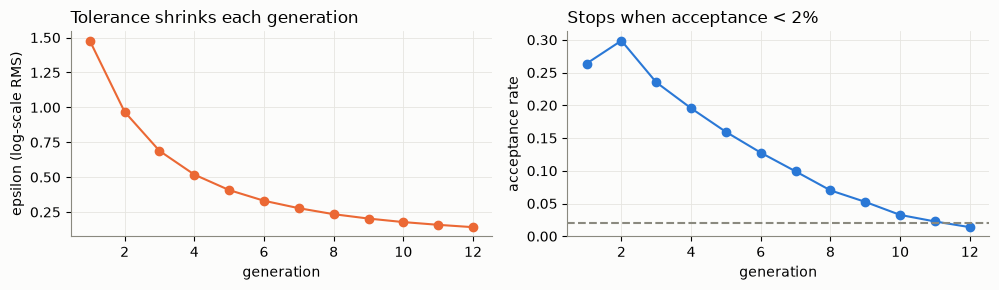

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(hist.index[1:], hist.epsilon[1:], "o-", color=MODEL_C)
ax[0].set_xlabel("generation"); ax[0].set_ylabel("epsilon (log-scale RMS)")
ax[0].set_title("Tolerance shrinks each generation", loc="left")
ax[1].plot(hist.index[1:], hist.accept_rate[1:], "o-", color=DATA_C)
ax[1].axhline(C.ABC_MIN_ACCEPT_RATE, color=MUTED, ls="--")
ax[1].set_xlabel("generation"); ax[1].set_ylabel("acceptance rate")
ax[1].set_title("Stops when acceptance < 2%", loc="left")
plt.tight_layout(); plt.show()

### Posterior vs. truth

`post.summary()` gives weighted quantiles in natural units. The dashed line in each panel is the
generator's true value (known only because the data are synthetic).

,parameter,q10,q50,q90
0,gamma_pre,0.033,0.076,0.153
1,delta_pre,0.785,0.912,1.067
2,gamma_post,0.025,0.076,0.187
3,delta_post,0.403,0.552,0.786
4,q_surgery,0.091,0.119,0.161
5,ca125_0,472.915,555.561,634.313
6,shift_gamma,-0.772,-0.019,0.619
7,shift_delta,-0.777,-0.499,-0.191


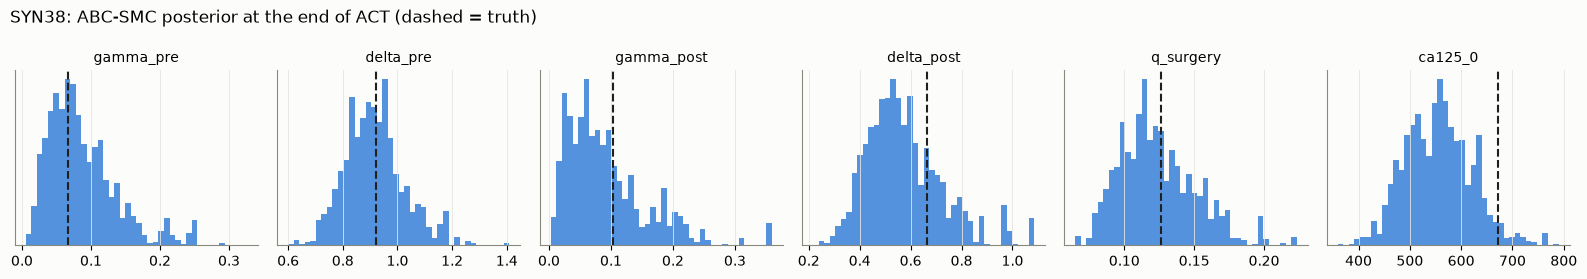

In [7]:
display(post.summary().round(3))

nat = post.natural()
cols = ["gamma_pre", "delta_pre", "gamma_post", "delta_post", "q_surgery", "ca125_0"]
fig, axes = plt.subplots(1, len(cols), figsize=(16, 2.8))
for ax, c in zip(axes, cols):
    ax.hist(nat[c], bins=40, weights=post.weights, color=DATA_C, alpha=0.8)
    ax.axvline(true_row[c], color=INK, ls="--", lw=1.5)
    ax.set_title(c, fontsize=10); ax.set_yticks([])
plt.suptitle(f"{pid}: ABC-SMC posterior at the end of ACT (dashed = truth)", x=0.01, ha="left")
plt.tight_layout(); plt.show()

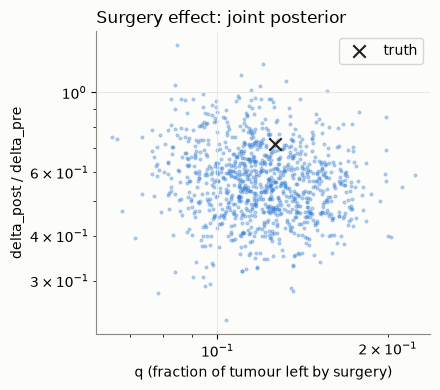

In [8]:
# the surgery effect: tumour removed (q) vs. change in kill rate (shift_delta) are partly
# interchangeable, so look at them jointly
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(nat.q_surgery, np.exp(nat.shift_delta), s=4, alpha=0.3, color=DATA_C)
ax.scatter([true_row.q_surgery], [true_row.delta_post / true_row.delta_pre], s=80, marker="x",
           color=INK, label="truth")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("q (fraction of tumour left by surgery)")
ax.set_ylabel("delta_post / delta_pre")
ax.set_title("Surgery effect: joint posterior", loc="left"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Forecast from `t_now`

`post.forecast()` simulates posterior draws forward:
- `fc.band()`: model value only (parameter uncertainty);
- `fc.band(noisy=True)`: plus assay noise (what a future reading may show);
- `fc.recurrence_cdf(t)`, `fc.recurrence_interval(0.8)`, `fc.p_recur_within(12)`;
- `fc.next_visit(rule="risk", p=0.1)`: first time the chance that CA-125 has crossed 35 since
  `t_now` reaches 10% (kept between 1 and 6 months ahead).

recurrence (months after ACT): median > 36, 80% interval [15.2, > 36]; true 28.2
P(recur within 6 / 12 months) = 0.00 / 0.03
suggested next visit: month 17.00 (6.0 months after t_now)


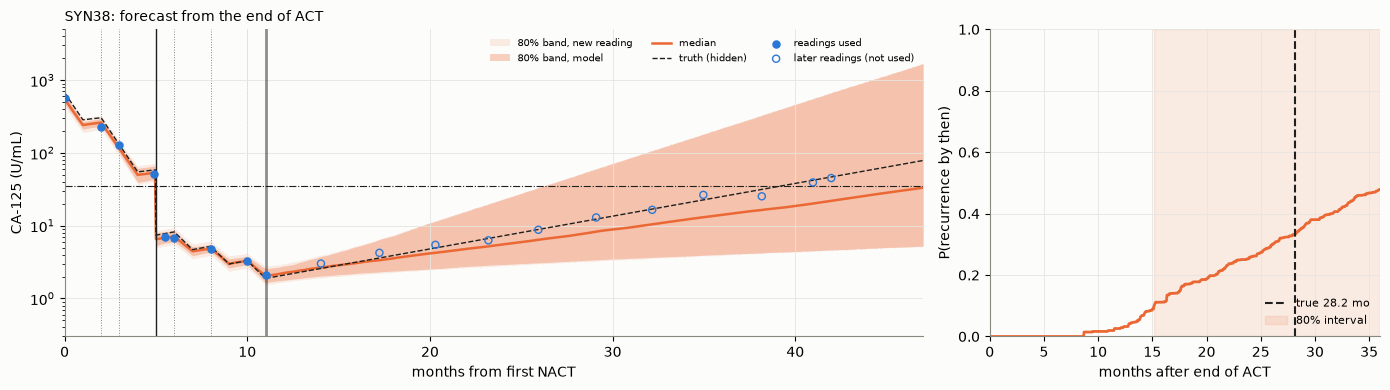

In [9]:
def plot_forecast(post, fc, daily, title, ax=None, ax2=None, show_future=True):
    s = post.schedule
    if ax is None:
        fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2.2, 1]})
    b, bn = fc.band(), fc.band(noisy=True)
    ax.fill_between(bn.t, bn.q10, bn.q90, color=MODEL_C, alpha=0.12, lw=0,
                    label="80% band, new reading")
    ax.fill_between(b.t, b.q10, b.q90, color=MODEL_C, alpha=0.30, lw=0, label="80% band, model")
    ax.plot(b.t, b.q50, color=MODEL_C, lw=1.8, label="median")
    tt = daily.time.values / C.DAYS_PER_MONTH
    ax.plot(tt, daily.tumor_burden, color=INK, ls="--", lw=1, label="truth (hidden)")
    used = post.t_obs
    ax.scatter(used, post.y_obs, s=26, color=DATA_C, zorder=4, label="readings used")
    if show_future:
        v = daily[(daily.visit == 1) & (daily.time / C.DAYS_PER_MONTH > post.t_now + 1e-9)]
        ax.scatter(v.time / C.DAYS_PER_MONTH, v.CA125, s=26, facecolor="none", edgecolor=DATA_C,
                   zorder=4, label="later readings (not used)")
    for x in np.concatenate([s.nact_starts, s.act_starts]):
        ax.axvline(x, color=MUTED, ls=":", lw=0.7, zorder=0)
    ax.axvline(s.t_surgery, color=INK, lw=1)
    ax.axvline(post.t_now, color=INK, lw=2, alpha=0.5)
    ax.axhline(CUT, color=INK, ls="-.", lw=0.8)
    ax.set_yscale("log"); ax.set_ylim(0.3, 5e3); ax.set_xlim(0, fc.t[-1])
    ax.set_xlabel("months from first NACT"); ax.set_ylabel("CA-125 (U/mL)")
    ax.set_title(title, loc="left", fontsize=10)
    ax.legend(fontsize=7, ncol=3, loc="upper right", frameon=False)
    rel = fc.t - s.t_end
    ax2.plot(rel, fc.recurrence_cdf(), color=MODEL_C, lw=2)
    true_rel = daily.iloc[0].true_recurrence_rel
    if np.isfinite(true_rel):
        ax2.axvline(true_rel, color=INK, ls="--", label=f"true {true_rel:.1f} mo")
    lo, md_, hi = fc.recurrence_interval(0.8, cap=C.FOLLOWUP_MONTHS)
    ax2.axvspan(lo, hi, color=MODEL_C, alpha=0.12, label="80% interval")
    ax2.set_xlim(0, C.FOLLOWUP_MONTHS); ax2.set_ylim(0, 1)
    ax2.set_xlabel("months after end of ACT"); ax2.set_ylabel("P(recurrence by then)")
    ax2.legend(fontsize=8, frameon=False, loc="lower right")
    return ax, ax2


CAP = C.FOLLOWUP_MONTHS + 1          # "no recurrence within follow-up" shown as 37


def fmt(v):
    return f"> {C.FOLLOWUP_MONTHS}" if v >= CAP else f"{v:.1f}"


fc = post.forecast()
lo, md_, hi = fc.recurrence_interval(0.8, cap=CAP)
t_next = fc.next_visit(rule="risk", p=0.10)
print(f"recurrence (months after ACT): median {fmt(md_)}, 80% interval [{fmt(lo)}, {fmt(hi)}]; "
      f"true {fmt(min(true_row.true_recurrence_rel, CAP))}")
print(f"P(recur within 6 / 12 months) = {fc.p_recur_within(6):.2f} / {fc.p_recur_within(12):.2f}")
print(f"suggested next visit: month {t_next:.2f} ({t_next - t_now:.1f} months after t_now)")
plot_forecast(post, fc, daily, f"{pid}: forecast from the end of ACT")
plt.tight_layout(); plt.show()

## 5. Same patient at later time points

Refit with more readings (`t_now` = end of ACT, +6, +12 months) and see the interval narrow.

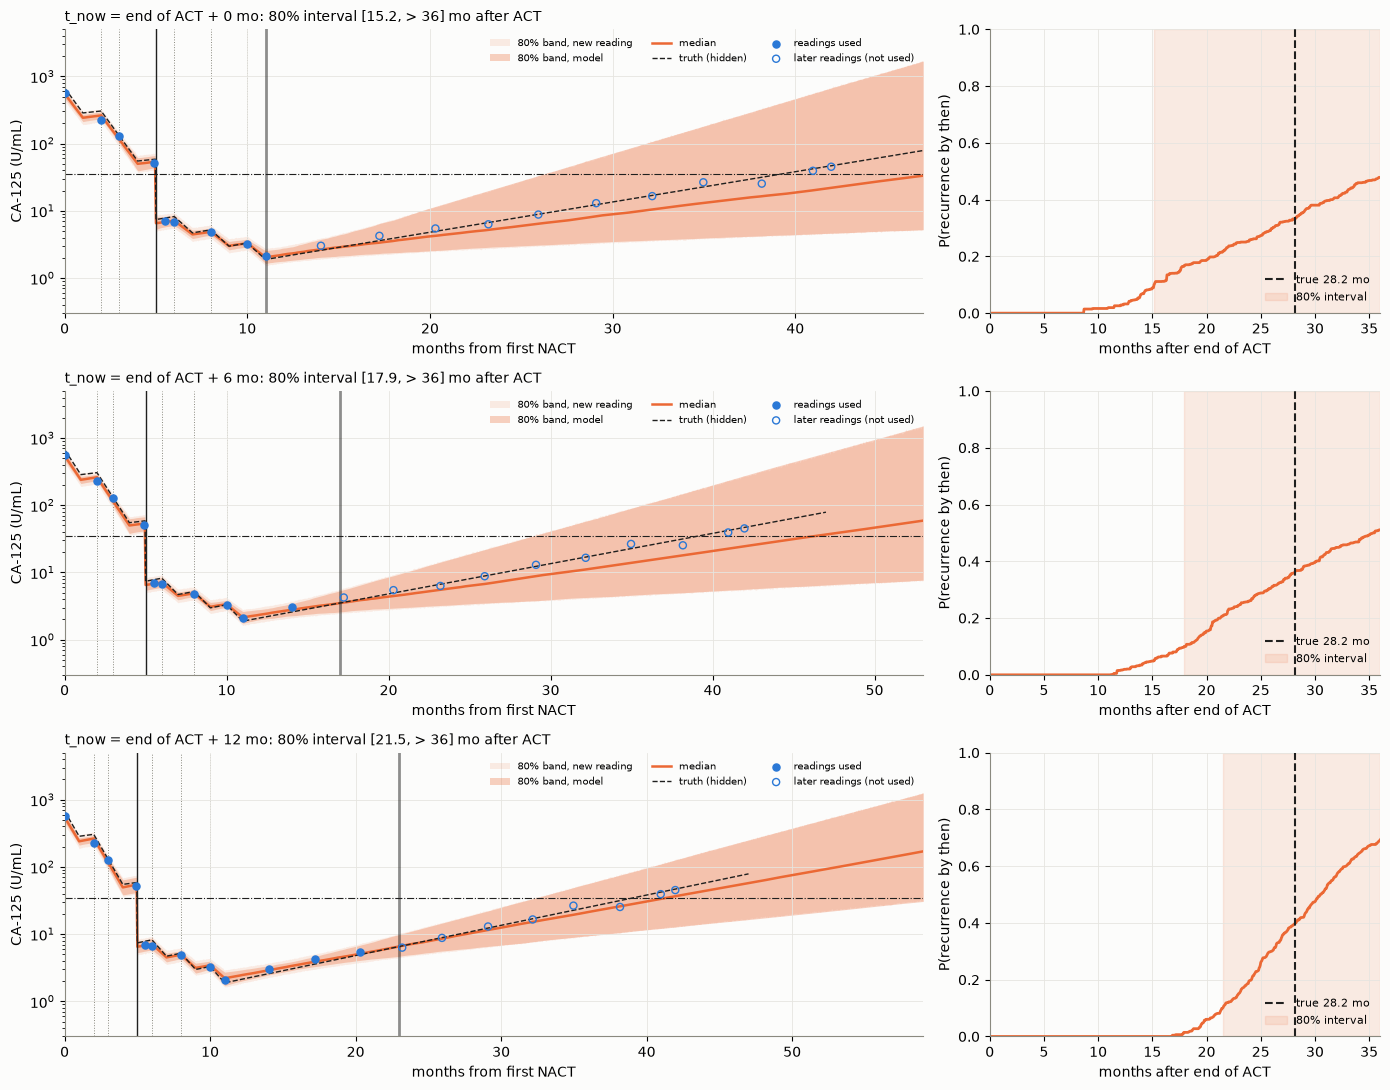

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(14, 11), gridspec_kw={"width_ratios": [2.2, 1]})
for row, k in zip(axes, [0, 6, 12]):
    tn = sched.t_end + k
    if true_row.t_detected <= tn:
        row[0].set_title(f"+{k} mo: already detected", loc="left"); continue
    p_k = A.fit(model, t_obs, y_obs, sched, t_now=tn, prior=A.prior_for(SPEC, y_obs[0]))
    f_k = p_k.forecast()
    lo, md_, hi = f_k.recurrence_interval(0.8, cap=CAP)
    plot_forecast(p_k, f_k, daily, f"t_now = end of ACT + {k} mo: 80% interval "
                  f"[{fmt(lo)}, {fmt(hi)}] mo after ACT", row[0], row[1])
plt.tight_layout(); plt.show()

## 6. Time decay

`decay=τ` (months) down-weights old readings, $w_i = e^{-(t_\text{now}-t_i)/\tau}$.
Small τ trusts recent readings more (useful if the patient's dynamics drift); it also throws away
information, so intervals get wider.

In [11]:
tn = sched.t_end + 6 if true_row.t_detected > sched.t_end + 6 else sched.t_end
rows = []
for decay in [None, 12, 6, 3]:
    p_d = A.fit(model, t_obs, y_obs, sched, t_now=tn, prior=A.prior_for(SPEC, y_obs[0]),
                decay=decay)
    lo, md_, hi = p_d.forecast().recurrence_interval(0.8, cap=CAP)
    rows.append(dict(decay=str(decay), low=lo, median=md_, high=hi, width=hi - lo))
print(f"values of {CAP} mean 'no recurrence within {C.FOLLOWUP_MONTHS} months'")
pd.DataFrame(rows).round(1)

values of 37 mean 'no recurrence within 36 months'


,decay,low,median,high,width
0,None,17.9,35.3,37,19.1
1,12,18.3,34.5,37,18.7
2,6,17.2,33.3,37,19.8
3,3,17.2,31.2,37,19.8


## 7. Adaptive follow-up: forecast → next visit → measure → update

Pipeline for one patient, starting at the end of ACT:
1. fit with readings so far; forecast;
2. `next_visit(rule="risk", p=0.10)` gives the next visit;
3. "measure" CA-125 that day (from the daily synthetic data);
4. record how surprising the reading was (`fc.surprise`: probability of an outcome at least as
   unusual; small = surprising, e.g. < 0.05) and refit with `post.update`;
5. stop when a reading ≥ 35 is seen (detected recurrence) or 36 months after ACT.

In [12]:
def adaptive_followup(model, data, pid, spec, rule="risk", p=0.10, max_gap=6.0, decay=None,
                      censor_below=None, max_visits=20):
    t_obs, y_obs, s, daily = A.patient_inputs(data, pid)
    keep = t_obs <= s.t_end + 1e-9                     # standard visits up to the end of ACT
    t_obs, y_obs = t_obs[keep], y_obs[keep]
    by_day = daily.set_index("time")
    post = A.fit(model, t_obs, y_obs, s, t_now=s.t_end, prior=A.prior_for(spec, y_obs[0]),
                 decay=decay, censor_below=censor_below)
    steps = []
    for _ in range(max_visits):
        fc = post.forecast()
        lo, md_, hi = fc.recurrence_interval(0.8, cap=CAP)
        t_next = fc.next_visit(rule=rule, p=p, max_gap=max_gap)
        day = int(round(t_next * C.DAYS_PER_MONTH))
        if day not in by_day.index:                      # past the end of follow-up
            steps.append(dict(t_now=post.t_now, lo=lo, med=md_, hi=hi, t_next=np.nan,
                              y_next=np.nan, surprise=np.nan))
            break
        y_next = float(by_day.loc[day, "CA125"])
        steps.append(dict(t_now=post.t_now, lo=lo, med=md_, hi=hi, t_next=day / C.DAYS_PER_MONTH,
                          y_next=y_next, surprise=fc.surprise(day / C.DAYS_PER_MONTH, y_next)))
        if y_next >= CUT:
            break
        post = post.update(day / C.DAYS_PER_MONTH, y_next)
    return pd.DataFrame(steps), post, daily


t0 = time.time()
steps, post_last, daily = adaptive_followup(model, data, pid, SPEC)
print(f"{pid}: {len(steps)} adaptive visits in {time.time() - t0:.0f} s")
steps.assign(width=steps.hi - steps.lo).round(2)

SYN38: 6 adaptive visits in 7 s


,t_now,lo,med,hi,t_next,y_next,surprise,width
0,11.0,15.19,37.00,37.00,17.0,4.39,0.54,21.81
1,17.0,17.71,28.14,37.00,23.0,7.77,0.89,19.29
2,23.0,20.93,26.54,37.00,29.0,8.60,0.20,16.07
3,29.0,27.41,33.38,37.00,35.0,25.75,0.19,9.59
4,35.0,26.05,29.25,34.01,37.1,30.34,0.59,7.95
5,37.1,26.84,28.89,32.47,38.1,42.11,0.08,5.63


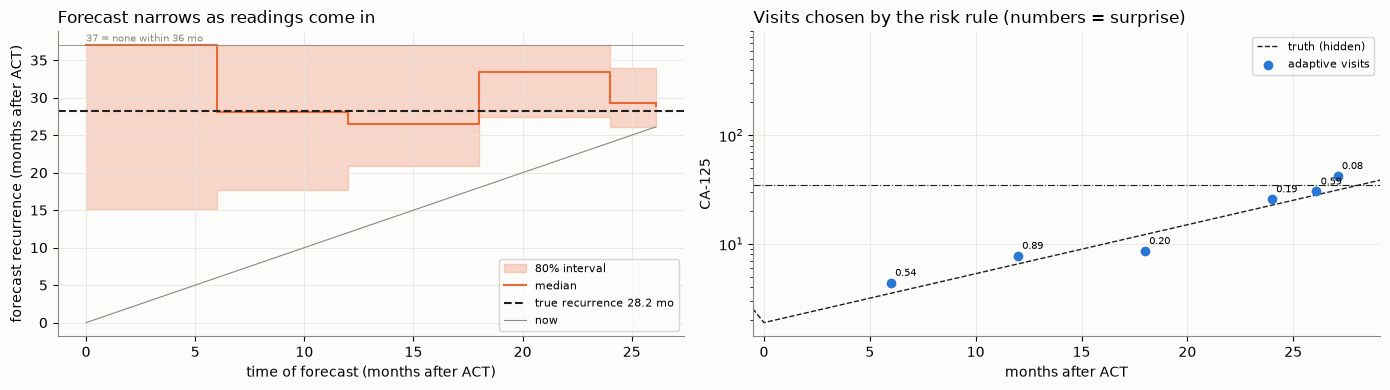

In [13]:
s = A.patient_inputs(data, pid)[2]
true_rel = daily.iloc[0].true_recurrence_rel
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
x = steps.t_now - s.t_end
ax[0].fill_between(x, steps.lo, steps.hi, step="post", color=MODEL_C, alpha=0.25,
                   label="80% interval")
ax[0].step(x, steps.med, where="post", color=MODEL_C, label="median")
ax[0].axhline(CAP, color=MUTED, lw=0.6)
ax[0].text(0, CAP + 0.5, "37 = none within 36 mo", fontsize=7, color=MUTED)
if np.isfinite(true_rel):
    ax[0].axhline(true_rel, color=INK, ls="--", label=f"true recurrence {true_rel:.1f} mo")
ax[0].plot(x, x, color=MUTED, lw=0.8, label="now")
ax[0].set_xlabel("time of forecast (months after ACT)")
ax[0].set_ylabel("forecast recurrence (months after ACT)")
ax[0].set_title("Forecast narrows as readings come in", loc="left"); ax[0].legend(fontsize=8)
tt = daily.time / C.DAYS_PER_MONTH - s.t_end
ax[1].plot(tt, daily.tumor_burden, color=INK, ls="--", lw=1, label="truth (hidden)")
ax[1].scatter(steps.t_next - s.t_end, steps.y_next, color=DATA_C, zorder=3,
              label="adaptive visits")
for _, r in steps.dropna().iterrows():
    ax[1].annotate(f"{r.surprise:.2f}", (r.t_next - s.t_end, r.y_next), fontsize=7,
                   xytext=(3, 5), textcoords="offset points")
ax[1].axhline(CUT, color=INK, ls="-.", lw=0.8)
ax[1].set_yscale("log"); ax[1].set_xlim(-0.5, steps.t_next.max() - s.t_end + 2)
ax[1].set_xlabel("months after ACT"); ax[1].set_ylabel("CA-125")
ax[1].set_title("Visits chosen by the risk rule (numbers = surprise)", loc="left")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Adaptive vs. fixed 3-monthly visits, test patients

For each test patient: number of visits until detection and detection delay (detected time −
true time CA-125 reached 35). Two risk thresholds (p = 10% and 3%) against a fixed visit every
3 months after ACT, all on the same daily data. A lower p means earlier visits: more visits,
shorter delay. Takes a few minutes; lower `N_EVAL` to run faster.

In [14]:
def fixed_followup(d, s, every=3.0):
    by_day = d.set_index("time")
    days = [int(round((s.t_end + every * k) * C.DAYS_PER_MONTH))
            for k in range(1, int(C.FOLLOWUP_MONTHS / every) + 1)]
    days = [x for x in days if x in by_day.index]
    hit = [x for x in days if by_day.loc[x, "CA125"] >= CUT]
    return (days.index(hit[0]) + 1 if hit else len(days)), (hit[0] / C.DAYS_PER_MONTH if hit else np.inf)


def delay(t_det, true_abs):
    return t_det - true_abs if np.isfinite(t_det) and np.isfinite(true_abs) else np.nan


N_EVAL = len(test_ids)
rows = []
t0 = time.time()
for q_id in test_ids[:N_EVAL]:
    _, _, s_, d = A.patient_inputs(data, q_id)
    r = d.iloc[0]
    row = dict(patient=q_id, true_rel=r.true_recurrence_rel)
    n_fix, t_fix = fixed_followup(d, s_)
    row.update(fixed_visits=n_fix, fixed_delay=delay(t_fix, r.true_recurrence_abs))
    for p in (0.10, 0.03):
        st, _, _ = adaptive_followup(model, data, q_id, SPEC, p=p)
        det = st[st.y_next >= CUT]
        t_det = det.t_next.iloc[0] if len(det) else np.inf
        row.update({f"p{int(p * 100)}_visits": len(st.dropna(subset=["t_next"])),
                    f"p{int(p * 100)}_delay": delay(t_det, r.true_recurrence_abs)})
    rows.append(row)
cmp_ = pd.DataFrame(rows)
print(f"{N_EVAL} patients in {time.time() - t0:.0f} s")
rec = cmp_[np.isfinite(cmp_.true_rel) & (cmp_.true_rel > 0)]
summary = pd.DataFrame({
    "strategy": ["fixed every 3 mo", "adaptive, p = 10%", "adaptive, p = 3%"],
    "median visits": [rec.fixed_visits.median(), rec.p10_visits.median(), rec.p3_visits.median()],
    "median delay (mo)": [rec.fixed_delay.median(), rec.p10_delay.median(), rec.p3_delay.median()],
    "missed (not detected)": [rec.fixed_delay.isna().sum(), rec.p10_delay.isna().sum(),
                              rec.p3_delay.isna().sum()]})
print(f"patients who recurred after ACT: {len(rec)}")
summary.round(2)

30 patients in 441 s
patients who recurred after ACT: 25


,strategy,median visits,median delay (mo),missed (not detected)
0,fixed every 3 mo,6.0,1.45,0
1,"adaptive, p = 10%",6.0,0.20,0
2,"adaptive, p = 3%",6.0,0.68,0


In [15]:
cmp_.round(2)

,patient,true_rel,fixed_visits,fixed_delay,p10_visits,p10_delay,p3_visits,p3_delay
0,SYN31,22.94,8,1.06,8,-0.21,10,0.46
1,SYN32,22.19,8,1.81,6,-0.86,6,-2.19
2,SYN33,0.00,1,3.00,1,1.00,1,1.00
3,SYN34,2.79,1,0.21,2,-0.49,3,0.21
4,SYN35,inf,12,NaN,7,NaN,9,NaN
5,SYN36,9.02,3,-0.02,4,-0.52,6,0.68
6,SYN37,12.30,4,-0.30,4,-1.30,6,0.90
7,SYN38,28.18,10,1.82,6,-1.08,10,1.82
8,SYN39,inf,12,NaN,6,NaN,6,NaN
9,SYN40,35.32,11,-2.32,10,0.18,11,-2.32


## 7b. Exact vs. censored low readings

By default the readings below 35 are used as they are. With `censor_below=35` (the workshop RMSE
convention: below 35 counts as 0) a low reading only says "below 35". After surgery most readings
are below 35, so censoring throws away the regrowth they show: "below 35" rules out fast regrowth
but not slow regrowth, so the upper end of the recurrence interval stays at "none within 36
months". Same patient, same adaptive loop:

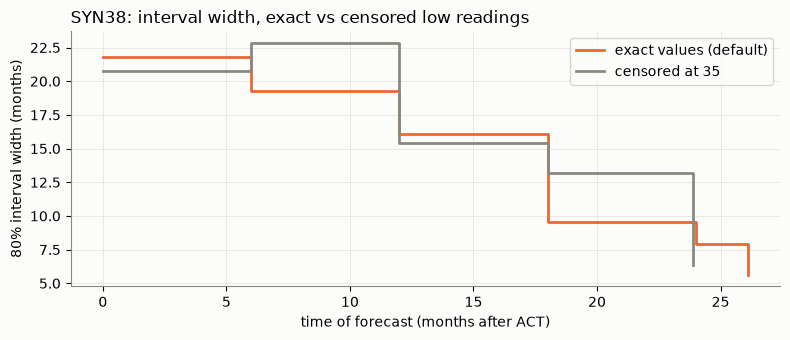

,readings,months_after_ACT,low,median,high,width
0,exact values (default),0.0,15.2,37.0,37.0,21.8
1,exact values (default),6.0,17.7,28.1,37.0,19.3
2,exact values (default),12.0,20.9,26.5,37.0,16.1
3,exact values (default),18.0,27.4,33.4,37.0,9.6
4,exact values (default),24.0,26.1,29.2,34.0,8.0
5,exact values (default),26.1,26.8,28.9,32.5,5.6
6,censored at 35,0.0,16.3,37.0,37.0,20.7
7,censored at 35,6.0,14.2,37.0,37.0,22.8
8,censored at 35,12.0,21.6,37.0,37.0,15.4
9,censored at 35,18.0,23.8,37.0,37.0,13.2


In [16]:
rows = []
for cens, name in [(None, "exact values (default)"), (CUT, "censored at 35")]:
    st, _, _ = adaptive_followup(model, data, pid, SPEC, censor_below=cens)
    for _, r in st.iterrows():
        rows.append(dict(readings=name, months_after_ACT=r.t_now - sched.t_end,
                         low=r.lo, median=r.med, high=r.hi, width=r.hi - r.lo))
cens_tab = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 3.5))
for (name, g), c in zip(cens_tab.groupby("readings", sort=False), [MODEL_C, MUTED]):
    ax.step(g.months_after_ACT, g.width, where="post", color=c, lw=2, label=name)
ax.set_xlabel("time of forecast (months after ACT)")
ax.set_ylabel("80% interval width (months)")
ax.set_title(f"{pid}: interval width, exact vs censored low readings", loc="left")
ax.legend(); plt.tight_layout(); plt.show()
cens_tab.round(1)

## 8. Calibration over test patients

Are the 80% intervals right about 80% of the time? Refit every test patient at three time
points (skipping those already detected) and check whether the true recurrence time is inside.

In [17]:
cap = C.FOLLOWUP_MONTHS + 1
rows = []
t0 = time.time()
for q_id in test_ids:
    t_o, y_o, s_, d = A.patient_inputs(data, q_id)
    r = d.iloc[0]
    true = min(r.true_recurrence_rel, cap)
    for name, k in [("end of ACT", 0), ("+6 mo", 6), ("+12 mo", 12)]:
        tn = s_.t_end + k
        if r.t_detected <= tn:
            continue
        p_ = A.fit(model, t_o, y_o, s_, t_now=tn, prior=A.prior_for(SPEC, y_o[0]))
        lo, md_, hi = p_.forecast().recurrence_interval(0.8, cap=cap)
        rows.append(dict(patient=q_id, landmark=name, covered=lo <= true <= hi, width=hi - lo))
cal = pd.DataFrame(rows)
print(f"{time.time() - t0:.0f} s")
cal.groupby("landmark", sort=False).agg(n=("covered", "size"), coverage_80=("covered", "mean"),
                                        median_width_months=("width", "median")).round(2)

88 s


,n,coverage_80,median_width_months
landmark,,,
end of ACT,30,1.00,23.81
+6 mo,25,0.92,20.34
+12 mo,19,1.00,10.35


## 9. Usage summary

```python
from ovca import abc_smc as A
from ovca.models import get_model

model = get_model("growth_death")                    # any BaseModel subclass
t_obs, y_obs, schedule, daily = A.patient_inputs(data, "SYN38")
prior = A.prior_for(A.default_prior_spec(model), y_obs[0])   # or empirical_prior_spec(model, fits)

post = A.fit(model, t_obs, y_obs, schedule, t_now=schedule.t_end, prior=prior,
             decay=None,            # or a time scale in months
             censor_below=None,     # default: use readings below 35; 35 = censor them
             n_particles=1000)
post.summary()                      # posterior quantiles (natural units)
fc = post.forecast(horizon=36)
fc.band(); fc.band(noisy=True)      # CA-125 bands over time
fc.recurrence_interval(0.8)         # (low, median, high), months after ACT; inf = none
fc.recurrence_interval(0.8, cap=37) # same, inf shown as 37
fc.p_recur_within(12)
t_next = fc.next_visit(rule="risk", p=0.10)       # or rule="width", width=1.0
post = post.update(t_next, y_new)   # add a reading and refit
fc.surprise(t_next, y_new)          # small = the new reading was surprising
```

**Another model.** Write a `BaseModel` subclass (see README). `fit` works with any model; for
speed, give it a vectorised `simulate_patient_batch` (the base class falls back to a loop).
Which parameters surgery may shift is set by `shift_params` (default `config.ABC_SHIFT_PARAMS`).

**Settings** live in `ovca/config.py` under `ABC_*`.

**Limits of this version.**
- The model here is deterministic; all forecast uncertainty is parameter + assay noise. A
  stochastic model plugs in the same way (the simulator just becomes random).
- `update` refits from the prior with all data (simple and stable, not the fastest).
- Readings below 35 are used as they are. If only "below 35" is known (no value),
  use `censor_below=35`; intervals are then much wider.